# Case Study 23 — Credit-Limit Increase and Customer Spend: Bootstrapping Skewed Metrics

**The bootstrap idea · percentile, basic and BCa intervals · stratified two-sample bootstrap · CIs for means, medians,
percentiles, ratios, shares and ratio metrics (spend per rupee of limit) · comparison with t-based intervals · tiny
samples · coverage simulation · when the bootstrap fails (extremes, very small n, dependent data) ·
permutation tests as a companion**

| | |
|---|---|
| **Domain** | Credit cards: credit-limit management |
| **Stakeholders** | Head of Credit Cards, Finance, Regional Cards Managers |
| **Difficulty** | Intermediate |
| **Importance** | 🟡 GOOD TO KNOW |
| **Builds on** | Case 01 (CIs, bootstrap basics), Case 04 (randomised tests), Case 15 (skew and rank tests) |
| **Data** | A randomised credit-limit test (2,500 vs 2,500 customers) and a tiny regional pilot (60 vs 60) |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A teaching-only answer key (the true population value of every metric,
> from a 3-million-customer simulation) is opened only in Section 12.

**What you will learn**

1. How the **bootstrap** gives a confidence interval for **any** statistic, not only the mean.
2. Which interval to use: **percentile**, **basic** or **BCa**, and when they differ.
3. How well it works, tested by **simulation**, and where it **fails**.
4. How to match the metric to the business question (typical customer, total money, big spenders, utilisation).

## Section 1 — Business context

The Head of Credit Cards ran a **randomised test**: a random half of 5,000 customers received a **25% credit-limit
increase**; the other half did not. Spend is measured as the average monthly card spend over the following three
months. The numbers are very skewed: most customers spend a few ten-thousands a month, **6% spend nothing**, and a
**handful of "whales" spend lakhs**.

> *"Finance wants to know what the limit increase does to spend. Averages are dominated by a few whales, so some
> people want medians; others say only totals matter for revenue. I need numbers with proper error bars for: average
> spend, typical spend, the ratio of spend with vs without the increase, the 90th percentile, the share of customers
> spending over ₹50,000 a month, and spend per rupee of limit. And the Western region ran its own tiny pilot with
> 60 vs 60 customers; the regional manager has the same questions."*

## Section 2 — Business questions

1. By how much does the limit increase change **average** spend, **typical** (median) spend, the 90th percentile
   and the share of big spenders?
2. What are the **confidence intervals**, and do they depend on how we compute them?
3. Does the **spend per rupee of limit** (utilisation) go up or down?
4. What can the **small pilot** say, and how much should we trust its intervals?
5. How well does the bootstrap work, and when does it fail?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Effect on average / typical spend | Difference and ratio of means and of medians, between randomised arms | Stratified bootstrap |
| 2 | Do the CIs depend on the method? | Percentile vs basic vs BCa vs t | Compare intervals; coverage simulation |
| 3 | Utilisation | Ratio-of-sums statistic: total spend ÷ total limit, per arm | Bootstrap over customers (resample spend and limit together) |
| 4 | Small pilot | Same metrics, n = 60 per arm | Bootstrap, BCa, permutation test |
| 5 | Reliability | Actual coverage of a "95%" interval; failure modes | Simulation |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "23_bootstrap_credit_limit_spend"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(2323)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
BIG = 50_000

## Section 4 — Load the data

In [2]:
big = pd.read_csv(PATHS["data"] / "limit_increase_test.csv")
small = pd.read_csv(PATHS["data"] / "limit_increase_pilot.csv")
for name, d in [("Main test", big), ("Western pilot", small)]:
    print(f"{name}: {len(d):,} customers; groups {d['group'].value_counts().to_dict()}; missing {d.isna().sum().sum()}")
display(big.head())
S1, L1 = big.loc[big["group"] == "increase", "avg_monthly_spend_next_3m"].to_numpy(float), big.loc[big["group"] == "increase", "limit_after"].to_numpy(float)
S0, L0 = big.loc[big["group"] == "control", "avg_monthly_spend_next_3m"].to_numpy(float), big.loc[big["group"] == "control", "limit_after"].to_numpy(float)
bal = big.groupby("group")[["tenure_months", "prior_avg_spend_6m", "limit_before"]].mean()
bal["prior spend (median)"] = big.groupby("group")["prior_avg_spend_6m"].median()
print("Randomisation check (pre-treatment variables):")
bal

Main test: 5,000 customers; groups {'increase': 2500, 'control': 2500}; missing 0
Western pilot: 120 customers; groups {'increase': 60, 'control': 60}; missing 0


,customer_id,group,tenure_months,prior_avg_spend_6m,limit_before,limit_after,avg_monthly_spend_next_3m
0,LI23100000,increase,86,"7,300.0000","57,000.0000","71,000.0000","20,381.0000"
1,LI23100001,increase,23,"36,828.0000","255,000.0000","319,000.0000","53,086.0000"
2,LI23100002,control,9,"13,956.0000","56,000.0000","56,000.0000","16,865.0000"
3,LI23100003,control,69,"12,827.0000","52,000.0000","52,000.0000","17,215.0000"
4,LI23100004,increase,45,"15,282.0000","88,000.0000","110,000.0000","39,498.0000"


Randomisation check (pre-treatment variables):


,tenure_months,prior_avg_spend_6m,limit_before,prior spend (median)
group,,,,
control,45.2368,"23,330.0920","128,869.6000","15,645.5000"
increase,44.6784,"23,310.9380","129,438.8000","15,742.5000"


Prior spend, tenure and limit before the test are balanced across arms, as expected from randomisation. We therefore
compare the **outcome** between arms directly.

## Section 5 — Descriptive statistics: how skewed is spend?

In [3]:
def describe(x):
    return {"n": len(x), "mean": x.mean(), "median": np.median(x), "SD": x.std(ddof=1), "90th percentile": np.percentile(x, 90), "99th percentile": np.percentile(x, 99),
            "maximum": x.max(), "share with zero spend": (x == 0).mean(), "share over ₹50,000": (x > BIG).mean(), "skewness": stats.skew(x),
            "top 1% share of total spend": np.sort(x)[-max(1, len(x) // 100):].sum() / x.sum()}
desc = pd.DataFrame({"control": describe(S0), "limit increase": describe(S1)})
save_table(desc, "descriptives", PATHS["tables"])
desc

,control,limit increase
n,"2,500.0000","2,500.0000"
mean,"28,279.5596","30,282.9376"
median,"14,792.5000","16,174.5000"
SD,"56,205.2124","65,094.6022"
90th percentile,"59,620.3000","66,284.2000"
99th percentile,"226,343.5600","213,702.6300"
maximum,"1,480,845.0000","2,122,096.0000"
share with zero spend,0.0524,0.0564
"share over ₹50,000",0.1336,0.1488
skewness,11.7196,17.7600


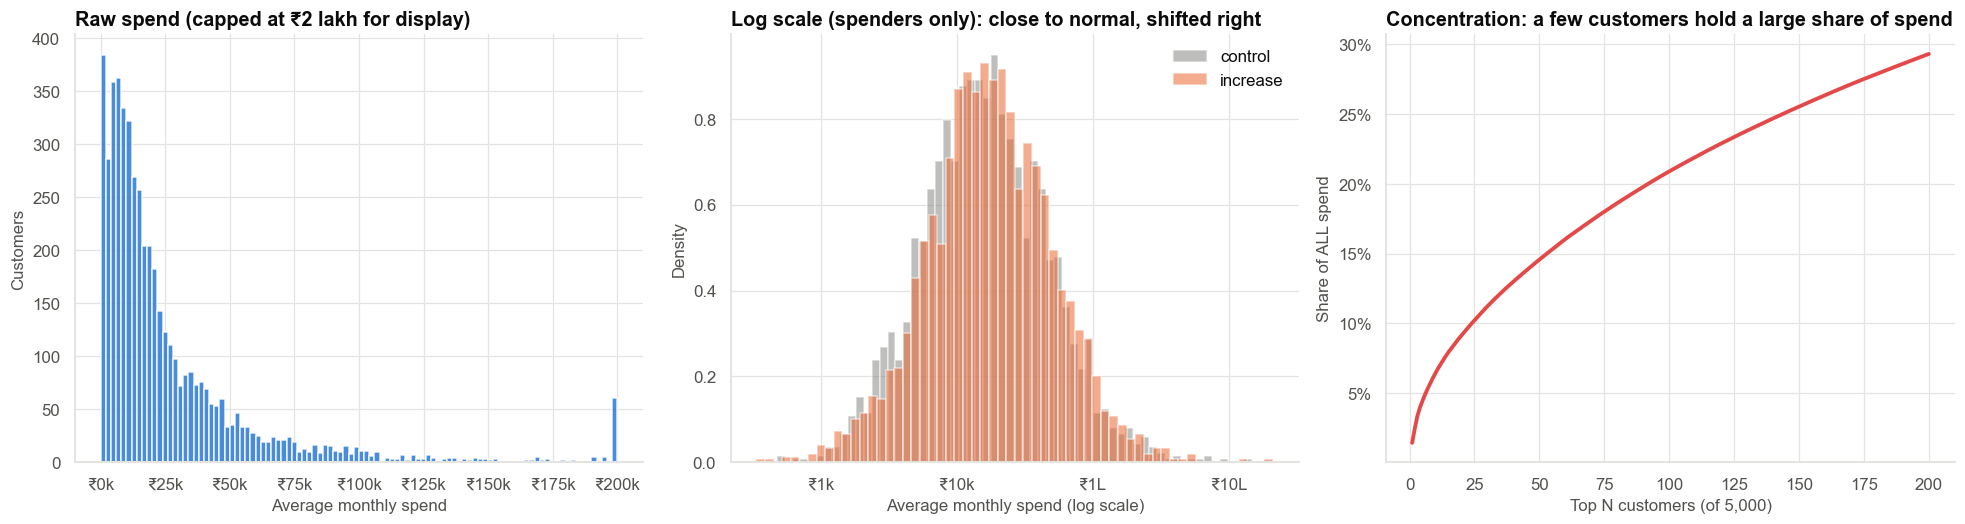

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))
ax = axes[0]
ax.hist(np.minimum(big["avg_monthly_spend_next_3m"], 200_000), bins=100, color=PRIMARY, alpha=0.85)
ax.xaxis.set_major_formatter(kfmt)
ax.set(title="Raw spend (capped at ₹2 lakh for display)", xlabel="Average monthly spend", ylabel="Customers")
ax = axes[1]
pos = big[big["avg_monthly_spend_next_3m"] > 0]
for g, c in [("control", INK_MUTED), ("increase", COLORS["orange"])]:
    ax.hist(np.log10(pos.loc[pos["group"] == g, "avg_monthly_spend_next_3m"]), bins=60, alpha=0.55, color=c, density=True, label=g)
ax.set_xticks(np.log10([1_000, 10_000, 100_000, 1_000_000]), ["₹1k", "₹10k", "₹1L", "₹10L"])
ax.set(title="Log scale (spenders only): close to normal, shifted right", xlabel="Average monthly spend (log scale)", ylabel="Density"); ax.legend(frameon=False)
ax = axes[2]
srt = np.sort(big["avg_monthly_spend_next_3m"].to_numpy())[::-1]
ax.plot(np.arange(1, len(srt) + 1)[:200], np.cumsum(srt)[:200] / srt.sum(), color=COLORS["red"], lw=2.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="Top N customers (of 5,000)", ylabel="Share of ALL spend", title="Concentration: a few customers hold a large share of spend")
fig.tight_layout()
save_fig(fig, "fig01_spend_distribution", PATHS["figures"])
plt.show()

**Observation.** Spend is **strongly right-skewed** (skewness about 12 in the control arm and 18 in the increase arm):
the mean is almost twice the median; 5–6% of customers spend nothing; the maximum is ₹15–21 lakh a month, many times the
99th percentile (about ₹2.1–2.3 lakh); and the **top 1% of customers (25 people) hold about 15% of all spend**. On a log
scale the spenders' distribution is close to normal.

**Interpretation.** For a metric like the **mean**, a handful of whales has an outsized effect: this is a single
statistic with a very **skewed sampling distribution** unless the sample is huge. The usual t-interval assumes that
distribution is approximately normal.

## Section 6 — Method selection: the bootstrap

**The idea.** We have one sample and want to know how much a statistic would vary across repeated samples. We can't
draw new samples from the population, but the sample is our best picture of it, so we **resample from the sample**
(with replacement), recompute the statistic each time, and use the spread of those values as an estimate of its
sampling variability.

**Recipe for a two-arm experiment (stratified bootstrap):**
1. Resample the control arm with replacement (same size); resample the treated arm separately (same size).
2. Compute the statistic (e.g. the difference in medians).
3. Repeat B = 5,000+ times.
4. Build an interval from the B values.

**Which interval?** (θ̂ = the estimate from the actual sample, θ*ᵦ = bootstrap values)

| Interval | Rule | Strength | Weakness |
|---|---|---|---|
| **Percentile** | 2.5th and 97.5th percentiles of θ* | Simple, transformation-respecting | Biased when θ* is skewed or biased |
| **Basic** (reverse percentile) | 2θ̂ − (97.5th, 2.5th percentiles of θ*) | Corrects some bias | Can go outside the natural range |
| **BCa** (bias-corrected and accelerated) | Percentiles of θ*, shifted by a **bias correction** z₀ and an **acceleration** a (from a jackknife) | Second-order accurate; handles skew and bias | More work; needs enough data |
| **t (normal theory)** | θ̂ ± t × SE | Fast | Assumes a normal sampling distribution |

**What the bootstrap does not fix.** Bias from non-random sampling; dependence between observations (iid
resampling); statistics driven by single extreme points (maximum); and very small samples.

## Section 7 — Bootstrap in action: the main test

In [5]:
B = 5000
n1, n0 = len(S1), len(S0)
I1 = rng.integers(0, n1, (B, n1)); I0 = rng.integers(0, n0, (B, n0))     # stratified: each arm resampled on its own, same indices for spend and limit
s1, l1, s0, l0 = S1[I1], L1[I1], S0[I0], L0[I0]

def pct_stat(q):
    return lambda S, L: np.percentile(S, q, axis=1)

# metric: (function on resampled arm matrices, combine)
METRICS = {
    "difference in means (₹)":            (lambda S, L: S.mean(1), "diff"),
    "ratio of means":                     (lambda S, L: S.mean(1), "ratio"),
    "difference in medians (₹)":          (lambda S, L: np.median(S, 1), "diff"),
    "ratio of medians":                   (lambda S, L: np.median(S, 1), "ratio"),
    "difference in 90th percentiles (₹)": (pct_stat(90), "diff"),
    "difference in share over ₹50,000 (pp)": (lambda S, L: 100 * (S > BIG).mean(1), "diff"),
    "difference in spend per rupee of limit (pp)": (lambda S, L: 100 * S.sum(1) / L.sum(1), "diff"),
}

def point(name, S1_, L1_, S0_, L0_):
    f, comb = METRICS[name]
    a, b = f(S1_[None, :], L1_[None, :])[0], f(S0_[None, :], L0_[None, :])[0]
    return a - b if comb == "diff" else a / b

def boot_dist(name, s1_, l1_, s0_, l0_):
    f, comb = METRICS[name]
    a, b = f(s1_, l1_), f(s0_, l0_)
    return a - b if comb == "diff" else a / b

def jackknife(name, S1_, L1_, S0_, L0_):
    out = []
    for i in range(len(S1_)):
        m = np.ones(len(S1_), bool); m[i] = False
        out.append(point(name, S1_[m], L1_[m], S0_, L0_))
    for i in range(len(S0_)):
        m = np.ones(len(S0_), bool); m[i] = False
        out.append(point(name, S1_, L1_, S0_[m], L0_[m]))
    return np.array(out)

def intervals(name, S1_, L1_, S0_, L0_, s1_, l1_, s0_, l0_, conf=0.95):
    theta = point(name, S1_, L1_, S0_, L0_)
    bd = boot_dist(name, s1_, l1_, s0_, l0_)
    a = (1 - conf) / 2
    pc = np.percentile(bd, [100 * a, 100 * (1 - a)])
    basic = [2 * theta - pc[1], 2 * theta - pc[0]]
    z0 = stats.norm.ppf(np.clip((bd < theta).mean() + 0.5 * (bd == theta).mean(), 1e-6, 1 - 1e-6))
    jk = jackknife(name, S1_, L1_, S0_, L0_)
    d = jk.mean() - jk
    acc = (d ** 3).sum() / (6 * ((d ** 2).sum()) ** 1.5) if (d ** 2).sum() > 0 else 0.0
    zs = stats.norm.ppf([a, 1 - a])
    adj = stats.norm.cdf(z0 + (z0 + zs) / (1 - acc * (z0 + zs)))
    bca = np.percentile(bd, 100 * adj)
    return {"estimate": theta, "boot SE": bd.std(ddof=1), "percentile": tuple(pc), "basic": tuple(basic), "BCa": tuple(bca), "z0 (bias)": z0, "a (acceleration)": acc, "dist": bd}

res_big = {name: intervals(name, S1, L1, S0, L0, s1, l1, s0, l0) for name in METRICS}

In [6]:
rows = []
for name, r in res_big.items():
    rows.append({"metric": name, "estimate": r["estimate"], "bootstrap SE": r["boot SE"],
                 "percentile low": r["percentile"][0], "percentile high": r["percentile"][1],
                 "BCa low": r["BCa"][0], "BCa high": r["BCa"][1], "basic low": r["basic"][0], "basic high": r["basic"][1],
                 "z0": r["z0 (bias)"], "acceleration a": r["a (acceleration)"]})
tab_big = pd.DataFrame(rows).set_index("metric")
# Classical benchmarks where they exist
m1, m0 = S1.mean(), S0.mean(); se_d = np.sqrt(S1.var(ddof=1) / n1 + S0.var(ddof=1) / n0)
tt = stats.ttest_ind(S1, S0, equal_var=False)
ci_t = tt.confidence_interval()
tab_big["Welch t low"] = np.nan; tab_big["Welch t high"] = np.nan
tab_big.loc["difference in means (₹)", ["Welch t low", "Welch t high"]] = [ci_t.low, ci_t.high]
save_table(tab_big, "main_test_intervals", PATHS["tables"])
display(tab_big[["estimate", "bootstrap SE", "percentile low", "percentile high", "BCa low", "BCa high", "Welch t low", "Welch t high"]])
sci = stats.bootstrap((S1, S0), lambda a, b, axis=-1: a.mean(axis=axis) - b.mean(axis=axis), n_resamples=5000, method="BCa", random_state=1, vectorized=True)
print(f"Cross-check with scipy.stats.bootstrap (BCa) for the difference in means: {sci.confidence_interval.low:,.0f} to {sci.confidence_interval.high:,.0f}  "
      f"vs ours {tab_big.loc['difference in means (₹)', 'BCa low']:,.0f} to {tab_big.loc['difference in means (₹)', 'BCa high']:,.0f}")

,estimate,bootstrap SE,percentile low,percentile high,BCa low,BCa high,Welch t low,Welch t high
metric,,,,,,,,
difference in means (₹),"2,003.3780","1,739.2275","-1,356.8552","5,495.8549","-1,140.8803","5,733.1366","-1,368.6699","5,375.4259"
ratio of means,1.0708,0.0633,0.9546,1.2039,0.9606,1.2121,NaN,NaN
difference in medians (₹),"1,382.0000",577.6210,308.9750,"2,587.0750",254.3718,"2,519.0559",NaN,NaN
ratio of medians,1.0934,0.0411,1.0203,1.1824,1.0175,1.1784,NaN,NaN
difference in 90th percentiles (₹),"6,663.9000","3,584.8214",-657.0725,"13,513.4575",-643.2242,"13,531.9709",NaN,NaN
"difference in share over ₹50,000 (pp)",1.5200,0.9899,-0.4000,3.4810,-0.3600,3.5557,NaN,NaN
difference in spend per rupee of limit (pp),-3.2285,1.0470,-5.3011,-1.1361,-5.2318,-1.0758,NaN,NaN


Cross-check with scipy.stats.bootstrap (BCa) for the difference in means: -1,271 to 5,565  vs ours -1,141 to 5,733


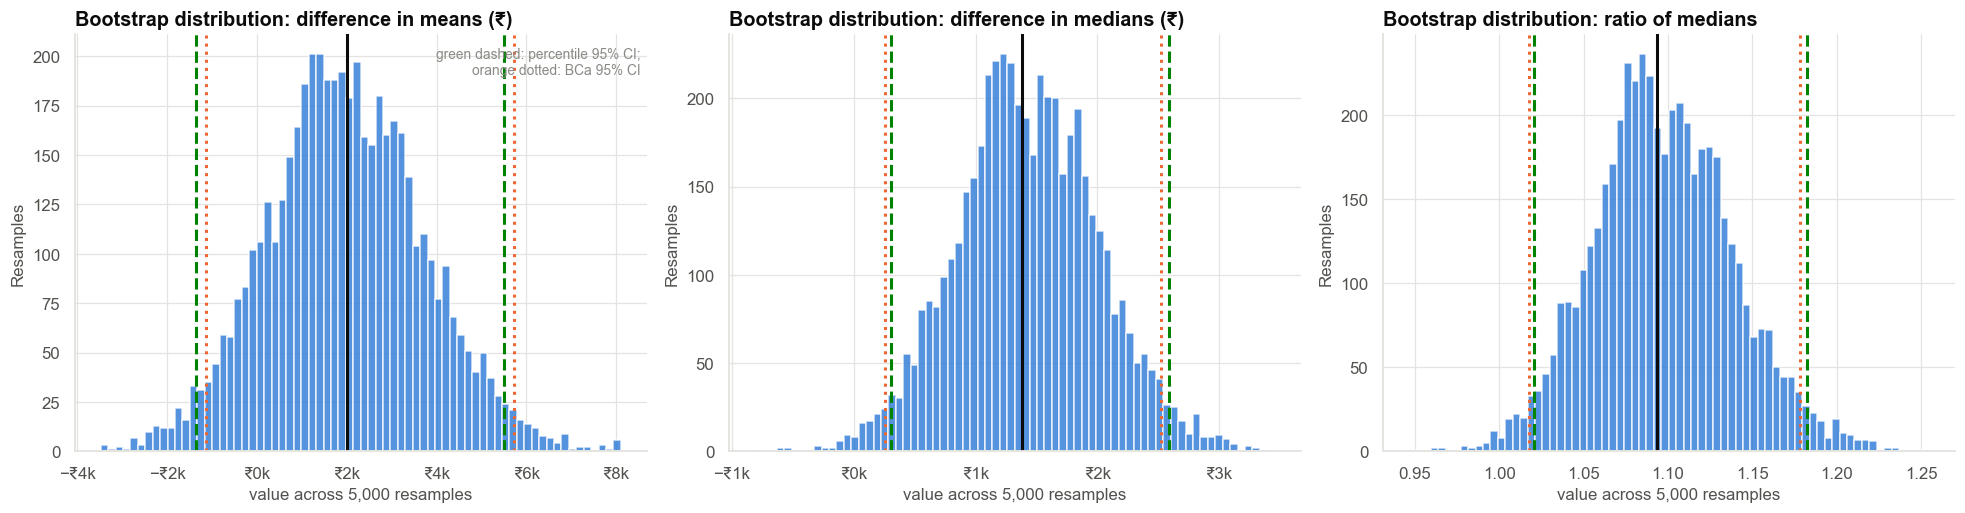

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, name, xf in [(axes[0], "difference in means (₹)", kfmt), (axes[1], "difference in medians (₹)", kfmt), (axes[2], "ratio of medians", None)]:
    r_ = res_big[name]
    ax.hist(r_["dist"], bins=70, color=PRIMARY, alpha=0.8)
    ax.axvline(r_["estimate"], color=INK, lw=2)
    for (lo, hi), c, ls in [(r_["percentile"], COLORS["green"], "--"), (r_["BCa"], COLORS["orange"], ":")]:
        ax.axvline(lo, color=c, ls=ls, lw=2); ax.axvline(hi, color=c, ls=ls, lw=2)
    if xf: ax.xaxis.set_major_formatter(xf)
    ax.set(title=f"Bootstrap distribution: {name}", xlabel="value across 5,000 resamples", ylabel="Resamples")
add_note(axes[0], "green dashed: percentile 95% CI;\norange dotted: BCa 95% CI", "upper right")
fig.tight_layout()
save_fig(fig, "fig02_bootstrap_distributions", PATHS["figures"])
plt.show()

**Observation.**
- The limit increase raises **average** monthly spend by about **₹2,000** per customer, but the 95% interval is wide
  (BCa about −₹1,100 to +₹5,700, **including zero**): whales make the mean very noisy.
- The **median** rises by about **₹1,400** (BCa CI about ₹250 to ₹2,500, excluding zero), a **ratio of medians** of about
  1.09 (CI about 1.02 to 1.18).
- The **90th percentile** rises by about ₹6,700, and the share of customers spending over ₹50,000 rises by about 1.5
  percentage points, but **both intervals include zero** (the tail is estimated imprecisely).
- **Spend per rupee of limit falls** by about 3 percentage points (CI about −5.2 to −1.1): spend rose roughly 7–9% but
  the limit rose 25%.
- With 2,500 customers per arm, the percentile, BCa and Welch t-intervals **nearly coincide**: bootstrap
  distributions are only mildly skewed and the bias and acceleration corrections are small. The methods differ
  mostly in small samples (Sections 8 and 9).
- Our BCa interval is close to `scipy.stats.bootstrap` (the difference is Monte Carlo noise from the resampling).

**Interpretation.** The same experiment gives a **clear** answer for the typical customer (median) and for utilisation,
but only a **noisy** answer for the mean and the upper tail. This is a property of the metric (whale-driven), not of
the bootstrap.

**Which metric answers which question?**

| Question | Metric | Why |
|---|---|---|
| "What happens to a typical customer?" | Median (or ratio of medians) | Robust to whales |
| "What happens to total spend (and revenue)?" | **Mean** (or ratio of means) | Totals = mean × customers; the whales are real revenue |
| "Who becomes a big spender?" | Share over a threshold; upper percentiles | Targets the high end |
| "Does the extra limit get used?" | Spend per rupee of limit (utilisation) | Utilisation drives risk and revenue per limit rupee |

### 7.1 A closer look at the bias and acceleration

In [8]:
ba = tab_big[["z0", "acceleration a"]].copy()
ba["interpretation"] = np.where(ba["acceleration a"].abs() > 0.02, "skewed sampling distribution: BCa shifts the interval", "close to symmetric")
save_table(ba, "bca_corrections", PATHS["tables"])
ba

,z0,acceleration a,interpretation
metric,,,
difference in means (₹),0.0401,0.0148,close to symmetric
ratio of means,0.0386,0.0105,close to symmetric
difference in medians (₹),-0.0481,0.0000,close to symmetric
ratio of medians,-0.0421,-0.0000,close to symmetric
difference in 90th percentiles (₹),0.0198,-0.0090,close to symmetric
"difference in share over ₹50,000 (pp)",0.0228,0.0001,close to symmetric
difference in spend per rupee of limit (pp),0.0175,0.0080,close to symmetric


**Reading z₀ and a.** z₀ (bias correction) measures how far the bootstrap distribution's centre is from the estimate; a
(acceleration) measures how quickly the standard error changes with the parameter (the skewness of the sampling
distribution). At this sample size all of them are small (the largest is about 0.05 for z₀ and 0.015 for a), which is why the
percentile and BCa intervals above are almost the same. They matter more in small samples (next section).

## Section 8 — The small regional pilot (60 vs 60)

In [9]:
ps1, pl1 = small.loc[small["group"] == "increase", "avg_monthly_spend_next_3m"].to_numpy(float), small.loc[small["group"] == "increase", "limit_after"].to_numpy(float)
ps0, pl0 = small.loc[small["group"] == "control", "avg_monthly_spend_next_3m"].to_numpy(float), small.loc[small["group"] == "control", "limit_after"].to_numpy(float)
Bs = 10_000
J1 = rng.integers(0, len(ps1), (Bs, len(ps1))); J0 = rng.integers(0, len(ps0), (Bs, len(ps0)))
res_small = {name: intervals(name, ps1, pl1, ps0, pl0, ps1[J1], pl1[J1], ps0[J0], pl0[J0]) for name in METRICS}
rows = []
for name, r in res_small.items():
    rows.append({"metric": name, "estimate": r["estimate"], "percentile low": r["percentile"][0], "percentile high": r["percentile"][1],
                 "BCa low": r["BCa"][0], "BCa high": r["BCa"][1], "basic low": r["basic"][0], "basic high": r["basic"][1], "z0": r["z0 (bias)"], "a": r["a (acceleration)"]})
tab_small = pd.DataFrame(rows).set_index("metric")
tt_s = stats.ttest_ind(ps1, ps0, equal_var=False); ci_s = tt_s.confidence_interval()
tab_small["Welch t low"] = np.nan; tab_small["Welch t high"] = np.nan
tab_small.loc["difference in means (₹)", ["Welch t low", "Welch t high"]] = [ci_s.low, ci_s.high]
save_table(tab_small, "pilot_intervals", PATHS["tables"])
display(tab_small[["estimate", "percentile low", "percentile high", "BCa low", "BCa high", "Welch t low", "Welch t high"]])
# Permutation test for the difference in medians (a hypothesis test, as a companion to the CI).
obs_d = np.median(ps1) - np.median(ps0)
allv = np.r_[ps1, ps0]; n_a = len(ps1)
perm = np.array([np.median(p_[:n_a]) - np.median(p_[n_a:]) for p_ in (rng.permutation(allv) for _ in range(10_000))])
p_perm = (np.abs(perm) >= abs(obs_d)).mean()
print(f"Pilot: difference in medians {obs_d:,.0f}; permutation test p = {p_perm:.3f};  Mann-Whitney p = {stats.mannwhitneyu(ps1, ps0).pvalue:.3f};  Welch t-test on means p = {tt_s.pvalue:.3f}")

,estimate,percentile low,percentile high,BCa low,BCa high,Welch t low,Welch t high
metric,,,,,,,
difference in means (₹),"12,610.4000","2,972.4500","23,210.1783","3,936.6661","24,793.8377","2,254.9623","22,965.8377"
ratio of means,1.7619,1.1607,2.6187,1.1864,2.6826,NaN,NaN
difference in medians (₹),"5,001.5000","-4,735.8875","15,200.1250","-4,753.3654","15,094.9507",NaN,NaN
ratio of medians,1.4679,0.6167,2.6284,0.6180,2.6388,NaN,NaN
difference in 90th percentiles (₹),"31,519.2000","9,682.1000","58,606.0000","5,678.8000","49,968.3000",NaN,NaN
"difference in share over ₹50,000 (pp)",15.0000,3.3333,26.6667,5.0000,28.3333,NaN,NaN
difference in spend per rupee of limit (pp),-2.4960,-7.8930,3.5736,-8.0177,3.3956,NaN,NaN


Pilot: difference in medians 5,002; permutation test p = 0.186;  Mann-Whitney p = 0.154;  Welch t-test on means p = 0.018


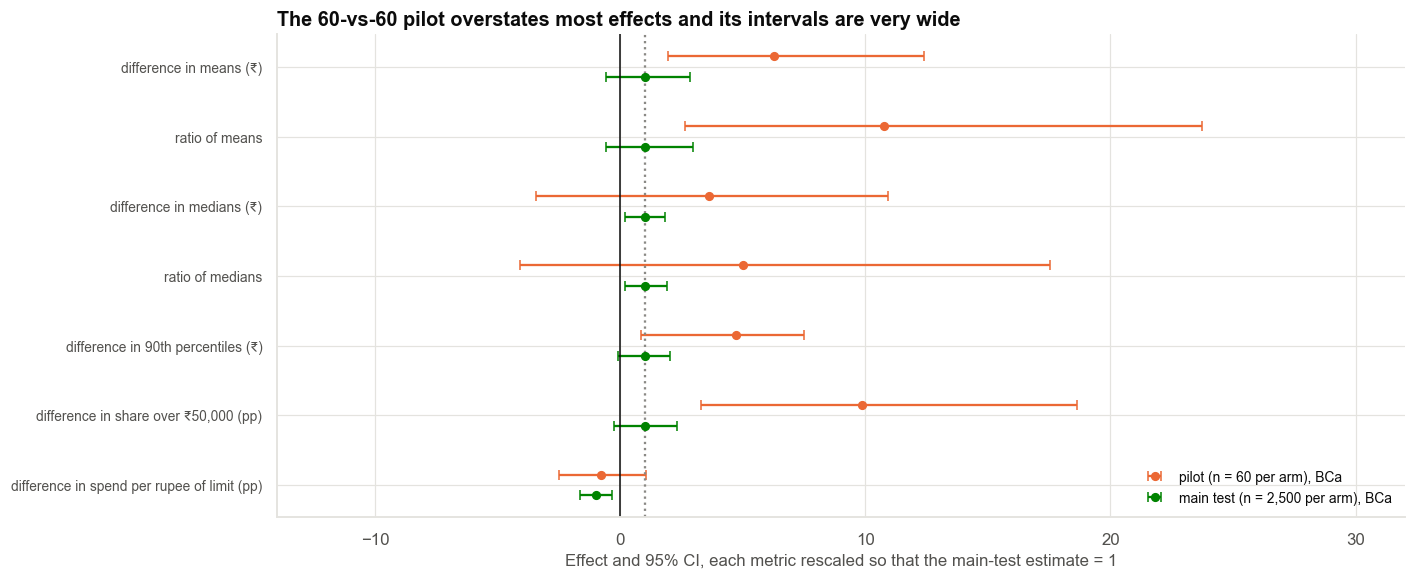

In [10]:
fig, ax = plt.subplots(figsize=(13, 5.4))
names = list(METRICS)
n_ = len(names)
for i, name in enumerate(names[::-1]):
    y_ = i
    for off, (lo, hi), c, lab in [(0.15, res_small[name]["BCa"], COLORS["orange"], "pilot (n = 60 per arm), BCa"),
                                  (-0.15, res_big[name]["BCa"], COLORS["green"], "main test (n = 2,500 per arm), BCa")]:
        est = res_small[name]["estimate"] if off > 0 else res_big[name]["estimate"]
        # Standardise each metric to its main-test estimate for a common axis
        scale = abs(res_big[name]["estimate"]) if res_big[name]["estimate"] != 0 else 1.0
        if "ratio" in name:
            ctr, f = 1.0, 1.0
            ax.errorbar((est - 1) / (abs(res_big[name]["estimate"] - 1)), y_ + off, xerr=[[(est - lo) / abs(res_big[name]["estimate"] - 1)], [(hi - est) / abs(res_big[name]["estimate"] - 1)]],
                        fmt="o", color=c, ms=5, capsize=3, label=lab if i == 0 else None)
        else:
            ax.errorbar(est / scale, y_ + off, xerr=[[(est - lo) / scale], [(hi - est) / scale]], fmt="o", color=c, ms=5, capsize=3, label=lab if i == 0 else None)
ax.axvline(0, color=INK, lw=1); ax.axvline(1, color=INK_MUTED, ls=":")
ax.set_yticks(range(n_), names[::-1], fontsize=9)
ax.set(xlabel="Effect and 95% CI, each metric rescaled so that the main-test estimate = 1", title="The 60-vs-60 pilot overstates most effects and its intervals are very wide")
ax.legend(frameon=False, loc="lower right", fontsize=9); ax.set_xlim(-14, 32)
fig.tight_layout()
save_fig(fig, "fig03_main_vs_pilot", PATHS["figures"])
plt.show()

**Observation.** In the pilot (60 vs 60 customers) the point estimates are **far larger** than in the main test:
the difference in means is about ₹12,600 (main test ₹2,000), the ratio of medians about 1.47 (main test 1.09) and the
share over ₹50,000 differs by 15 points (main test 1.5). The intervals are **many times wider** and the metrics
disagree among themselves: the mean difference looks **significant** (BCa CI ₹3,900 to ₹24,800; Welch p = 0.018) while the
median difference is **not** (CI about −₹4,800 to +₹15,100; permutation p = 0.19; Mann-Whitney p = 0.15). The
percentile, BCa and Welch intervals for the mean are similar to each other; none can repair a sample that happened to
contain different whales in the two arms.

**Interpretation.** The bootstrap gives an interval for **any** metric, but it can only describe the sample it is
given. In this pilot the control arm happened to contain few big spenders (control mean ₹16,600 vs ₹29,200 in the
increase arm), so the estimated effect is exaggerated and its significance is **not reliable** (compare the
winner's curse of Case 22). The regional pilot is too small to settle the question, and the main test, not the
pilot, should guide the decision.

## Section 9 — Does the bootstrap work? A coverage simulation

A 95% interval should contain the true value in 95% of repeated studies. We test this for **lognormal** data (σ = 1: very
skewed, like spend) with **one-sample** intervals for the mean and the median, using sample sizes 15, 30 and 100.

In [11]:
SIG = 1.0
TRUE_MEAN, TRUE_MED = np.exp(SIG ** 2 / 2), 1.0
def boot_ci_mean(x, B=1000, r=rng):
    idx = r.integers(0, len(x), (B, len(x)))
    bm = x[idx].mean(1)
    pc = np.percentile(bm, [2.5, 97.5])
    bt_se = x[idx].std(1, ddof=1) / np.sqrt(len(x))
    tstar = (bm - x.mean()) / np.where(bt_se > 0, bt_se, np.nan)
    q = np.nanpercentile(tstar, [2.5, 97.5])
    se = x.std(ddof=1) / np.sqrt(len(x))
    return pc, (x.mean() - q[1] * se, x.mean() - q[0] * se), bm

def bca_from(x, bm, stat):
    theta = stat(x); z0 = stats.norm.ppf(np.clip((bm < theta).mean(), 1e-6, 1 - 1e-6))
    jk = np.array([stat(np.delete(x, i)) for i in range(len(x))]); d = jk.mean() - jk
    acc = (d ** 3).sum() / (6 * ((d ** 2).sum()) ** 1.5) if (d ** 2).sum() > 0 else 0.0
    zs = stats.norm.ppf([0.025, 0.975])
    return np.percentile(bm, 100 * stats.norm.cdf(z0 + (z0 + zs) / (1 - acc * (z0 + zs))))

cov_rows = []
for n_ in [15, 30, 100]:
    hits = {k: 0 for k in ["mean: t", "mean: percentile", "mean: bootstrap-t", "mean: BCa", "median: percentile", "median: BCa"]}
    widths = {k: [] for k in hits}
    R = 600
    for _ in range(R):
        x = rng.lognormal(0, SIG, n_)
        t_ci = stats.t.interval(0.95, n_ - 1, loc=x.mean(), scale=stats.sem(x))
        pc, btt, bm = boot_ci_mean(x)
        bca = bca_from(x, bm, np.mean)
        idx = rng.integers(0, n_, (1000, n_)); bmed = np.median(x[idx], axis=1)
        pcm = np.percentile(bmed, [2.5, 97.5]); bcam = bca_from(x, bmed, np.median)
        for k, (lo, hi), tv in [("mean: t", t_ci, TRUE_MEAN), ("mean: percentile", pc, TRUE_MEAN), ("mean: bootstrap-t", btt, TRUE_MEAN), ("mean: BCa", bca, TRUE_MEAN),
                                ("median: percentile", pcm, TRUE_MED), ("median: BCa", bcam, TRUE_MED)]:
            hits[k] += (lo <= tv <= hi); widths[k].append(hi - lo)
    for k in hits:
        cov_rows.append({"n": n_, "interval": k, "coverage": hits[k] / R, "median width": np.median(widths[k])})
cov = pd.DataFrame(cov_rows)
cov_piv = cov.pivot(index="interval", columns="n", values="coverage")
save_table(cov, "coverage_simulation", PATHS["tables"])
print(f"Each cell: share of {R} simulated studies in which the nominal 95% interval contained the true value. Lognormal(0, 1) data; true mean {TRUE_MEAN:.2f}, true median 1.")
cov_piv

Each cell: share of 600 simulated studies in which the nominal 95% interval contained the true value. Lognormal(0, 1) data; true mean 1.65, true median 1.


n,15,30,100
interval,,,
mean: BCa,0.8467,0.8750,0.9333
mean: bootstrap-t,0.9217,0.9133,0.9500
mean: percentile,0.8317,0.8517,0.9333
mean: t,0.8417,0.8617,0.9333
median: BCa,0.9017,0.9300,0.9600
median: percentile,0.9250,0.9350,0.9617


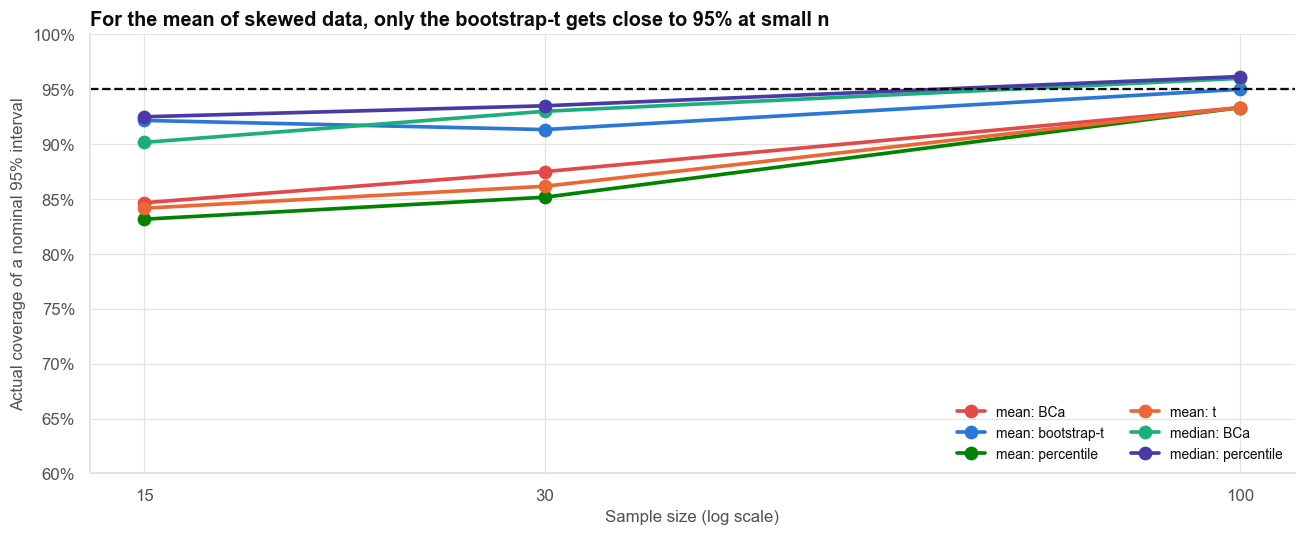

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
for k, c in zip(cov_piv.index, [COLORS["red"], COLORS["blue"], COLORS["green"], COLORS["orange"], COLORS["aqua"], COLORS["violet"]]):
    ax.plot(cov_piv.columns, cov_piv.loc[k], "o-", lw=2.4, ms=8, color=c, label=k)
ax.axhline(0.95, color=INK, ls="--", lw=1.5)
ax.set_xscale("log"); ax.set_xticks([15, 30, 100], ["15", "30", "100"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="Sample size (log scale)", ylabel="Actual coverage of a nominal 95% interval", ylim=(0.6, 1.0), title="For the mean of skewed data, only the bootstrap-t gets close to 95% at small n")
ax.legend(frameon=False, ncol=2, fontsize=9, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig04_coverage", PATHS["figures"])
plt.show()

**Observation.** For the **mean** of heavily skewed data:
- the **t-interval**, the **percentile bootstrap** and even **BCa** under-cover in small samples (about 83–85% at n = 15,
  85–88% at n = 30, 93% at n = 100, against the nominal 95%);
- only the **bootstrap-t** (which studentises each resample) comes close (about 92%, 91% and 95%);
- for the **median**, percentile and BCa intervals are both good (90–96%).

**Interpretation.** The bootstrap is **not magic**: it inherits the problems of a small, skewed sample (a typical
sample of 15 lognormal values does not contain the whales that drive the mean). The plain percentile interval is no
better than the t-interval here, BCa helps only a little, and the **bootstrap-t** is the best of the four for the mean.
Medians are much easier. The bootstrap is best viewed as a **large-sample** tool that is considerably more flexible
than normal theory.

## Section 10 — Where the bootstrap fails

In [13]:
fail_rows = []
R = 1000
# (a) The maximum: a bootstrap resample can never exceed the observed maximum.
hit_max = 0
for _ in range(R):
    x = rng.uniform(0, 1, 50); idx = rng.integers(0, 50, (1000, 50)); bm = x[idx].max(1)
    lo, hi = np.percentile(bm, [2.5, 97.5]); hit_max += (lo <= 1.0 <= hi)
fail_rows.append({"situation": "maximum of 50 uniform(0, 1) values (true maximum = 1)", "coverage of the nominal 95% bootstrap CI": hit_max / R})
# (b) Very small n
hit8 = 0
for _ in range(R):
    x = rng.lognormal(0, 1, 8); idx = rng.integers(0, 8, (1000, 8)); lo, hi = np.percentile(x[idx].mean(1), [2.5, 97.5]); hit8 += (lo <= TRUE_MEAN <= hi)
fail_rows.append({"situation": "mean of 8 lognormal values (percentile bootstrap)", "coverage of the nominal 95% bootstrap CI": hit8 / R})
# (c) Dependent data: AR(1) series; i.i.d. bootstrap vs moving-block bootstrap for the mean.
def ar1(n, rho, r):
    e = r.normal(0, 1, n + 50); x = np.zeros(n + 50)
    for t in range(1, n + 50):
        x[t] = rho * x[t - 1] + e[t]
    return x[50:]
hit_iid = hit_blk = 0
n_t, block = 200, 20
for _ in range(R // 2):
    x = ar1(n_t, 0.7, rng)
    idx = rng.integers(0, n_t, (500, n_t)); lo, hi = np.percentile(x[idx].mean(1), [2.5, 97.5]); hit_iid += (lo <= 0 <= hi)
    starts = rng.integers(0, n_t - block + 1, (500, n_t // block))
    bm = np.array([np.concatenate([x[s:s + block] for s in row]).mean() for row in starts]); lo, hi = np.percentile(bm, [2.5, 97.5]); hit_blk += (lo <= 0 <= hi)
fail_rows.append({"situation": "mean of an autocorrelated series (AR(1), ρ = 0.7, n = 200): i.i.d. bootstrap", "coverage of the nominal 95% bootstrap CI": hit_iid / (R // 2)})
fail_rows.append({"situation": "same series: moving-block bootstrap (blocks of 20)", "coverage of the nominal 95% bootstrap CI": hit_blk / (R // 2)})
fail = pd.DataFrame(fail_rows).set_index("situation")
save_table(fail, "bootstrap_failures", PATHS["tables"])
fail

,coverage of the nominal 95% bootstrap CI
situation,
"maximum of 50 uniform(0, 1) values (true maximum = 1)",0.0000
mean of 8 lognormal values (percentile bootstrap),0.7610
"mean of an autocorrelated series (AR(1), ρ = 0.7, n = 200): i.i.d. bootstrap",0.5800
same series: moving-block bootstrap (blocks of 20),0.8840


**Observation.**
- **Extremes:** the bootstrap CI for the maximum of a sample **never** contains the true maximum (coverage 0%),
  since no resample can exceed the observed maximum.
- **Tiny samples:** with 8 skewed values, coverage of a percentile-bootstrap CI for the mean is about 76%.
- **Dependence:** for an autocorrelated series, the i.i.d. bootstrap interval is **far too narrow** (coverage about
  58%); a **moving-block** bootstrap, which resamples chunks of consecutive observations, restores coverage to about
  88% (closer to nominal, though still short with only 200 points).

**Rules for using the bootstrap**

| Situation | Advice |
|---|---|
| Medians, percentiles, ratios, shares; n in the hundreds or more | Bootstrap works well; BCa is a sound default |
| Mean of a skewed variable, moderate n | Bootstrap-t (BCa only helps a little); not the plain percentile or t |
| n below about 30 and skewed data | Treat intervals as rough; consider a transformation (log) or a model |
| Extremes (max, min, very high quantiles) | The bootstrap fails; use extreme-value methods |
| Time series or clustered data | Resample blocks or clusters (customers, branches), not rows |
| Experiments | Resample **within** each arm (stratified), or use a permutation test for hypothesis tests |
| Resampling unit | The unit of **randomisation** (customer, branch, day): not the row |

## Section 11 — Matching the metric to the question: what is the business impact?

For Finance, the effect on **revenue** is the effect on **total spend** (the mean), which is the least certain metric.
We translate the main-test estimates into interchange revenue (assume 1.6% of spend) and show the interval:

In [14]:
IC = 0.016
d_mean = res_big["difference in means (₹)"]
rev = pd.DataFrame({"incremental monthly spend per customer (₹)": [d_mean["BCa"][0], d_mean["estimate"], d_mean["BCa"][1]]}, index=["BCa lower", "estimate", "BCa upper"])
rev["incremental annual interchange per customer (₹)"] = rev.iloc[:, 0] * 12 * IC
rev["…for 100,000 customers (₹ lakh)"] = rev["incremental annual interchange per customer (₹)"] * 100_000 / 1e5
save_table(rev, "revenue_impact", PATHS["tables"])
display(rev)
share_pos = (res_big["difference in means (₹)"]["dist"] > 0).mean()
print(f"Bootstrap probability that the true mean difference is positive: {share_pos:.0%}")

,incremental monthly spend per customer (₹),incremental annual interchange per customer (₹),"…for 100,000 customers (₹ lakh)"
BCa lower,"-1,140.8803",-219.0490,-219.0490
estimate,"2,003.3780",384.6486,384.6486
BCa upper,"5,733.1366","1,100.7622","1,100.7622"


Bootstrap probability that the true mean difference is positive: 87%


**Observation.** The point estimate implies about ₹385 of extra annual interchange per customer (about ₹385 lakh for
100,000 customers), but the interval runs from about −₹220 to +₹1,100, and the bootstrap distribution puts about an
87% probability on a positive effect. (This is revenue only; it ignores the extra credit-risk cost of a bigger limit
and the 3-point fall in utilisation.)

**Interpretation.** The robust finding (median up, utilisation down) says the increase **changes customers' behaviour**;
the revenue figure, which depends on whales, is **too noisy** to quote without its interval. A bigger test (or a
variance-reduction method, such as adjusting for prior spend, Case 04) would be needed to pin it down.

## Section 12 — Grading the intervals (using the answer key)

In [15]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv").set_index("metric")["true_value"]
key.index = [k.replace("Rs)", "₹)").replace("Rs ", "₹").replace("share spending over", "share over") for k in key.index]
g_rows = []
for name in METRICS:
    tv = key[name]
    for label, res in [("main test", res_big), ("pilot (60 vs 60)", res_small)]:
        r_ = res[name]
        g_rows.append({"metric": name, "data": label, "true value": tv, "estimate": r_["estimate"],
                       "percentile CI covers?": r_["percentile"][0] <= tv <= r_["percentile"][1],
                       "BCa CI covers?": r_["BCa"][0] <= tv <= r_["BCa"][1], "BCa width": r_["BCa"][1] - r_["BCa"][0]})
tv_tbl = pd.DataFrame(g_rows).set_index(["metric", "data"])
save_table(tv_tbl, "interval_grading", PATHS["tables"])
print(f"Intervals covering the truth — main test: BCa {tv_tbl.xs('main test', level='data')['BCa CI covers?'].mean():.0%}, percentile {tv_tbl.xs('main test', level='data')['percentile CI covers?'].mean():.0%};  "
      f"pilot: BCa {tv_tbl.xs('pilot (60 vs 60)', level='data')['BCa CI covers?'].mean():.0%}, percentile {tv_tbl.xs('pilot (60 vs 60)', level='data')['percentile CI covers?'].mean():.0%}")
tv_tbl

Intervals covering the truth — main test: BCa 100%, percentile 100%;  pilot: BCa 57%, percentile 43%


true value  \
metric                                      data                           
difference in means (₹)                     main test         2,846.1733   
                                            pilot (60 vs 60)  2,846.1733   
ratio of means                              main test             1.1027   
                                            pilot (60 vs 60)      1.1027   
difference in medians (₹)                   main test         1,552.2006   
                                            pilot (60 vs 60)  1,552.2006   
ratio of medians                            main test             1.1049   
                                            pilot (60 vs 60)      1.1049   
difference in 90th percentiles (₹)          main test         6,387.1911   
                                            pilot (60 vs 60)  6,387.1911   
difference in share over ₹50,000 (pp)       main test             2.0556   
                                            pilot (60 vs 60)      2.0556   
difference in spend per rupee of limit (pp) main test            -2.4593   
                                            pilot (60 vs 60)     -2.4593   

                                                                estimate  \
metric                                      data                           
difference in means (₹)                     main test         2,003.3780   
                                            pilot (60 vs 60) 12,610.4000   
ratio of means                              main test             1.0708   
                                            pilot (60 vs 60)      1.7619   
difference in medians (₹)                   main test         1,382.0000   
                                            pilot (60 vs 60)  5,001.5000   
ratio of medians                            main test             1.0934   
                                            pilot (60 vs 60)      1.4679   
difference in 90th percentiles (₹)          main test         6,663.9000   
                                            pilot (60 vs 60) 31,519.2000   
difference in share over ₹50,000 (pp)       main test             1.5200   
                                            pilot (60 vs 60)     15.0000   
difference in spend per rupee of limit (pp) main test            -3.2285   
                                            pilot (60 vs 60)     -2.4960   

                                                              percentile CI covers?  \
metric                                      data                                      
difference in means (₹)                     main test                          True   
                                            pilot (60 vs 60)                  False   
ratio of means                              main test                          True   
                                            pilot (60 vs 60)                  False   
difference in medians (₹)                   main test                          True   
                                            pilot (60 vs 60)                   True   
ratio of medians                            main test                          True   
                                            pilot (60 vs 60)                   True   
difference in 90th percentiles (₹)          main test                          True   
                                            pilot (60 vs 60)                  False   
difference in share over ₹50,000 (pp)       main test                          True   
                                            pilot (60 vs 60)                  False   
difference in spend per rupee of limit (pp) main test                          True   
                                            pilot (60 vs 60)                   True   

                                                              BCa CI covers?  \
metric                                      data                               
difference in means (₹)                     main test                   Tru

**Observation.** With 2,500 customers per arm every one of the seven metrics has a 95% interval that contains the true
population value, for both the percentile and the BCa method (7 of 7). Two things stand out:

- The **mean** is the metric with the largest miss: the main test estimated +₹2,003 against a true +₹2,846 (30% low), yet the
  interval (−₹1,141 to +₹5,733) covers it, because it is so wide (₹6,900).
- In the **60-vs-60 pilot** the BCa interval covers the truth for only **4 of 7** metrics (percentile: 3 of 7). It misses the
  mean difference (estimate +₹12,600, truth +₹2,846), the ratio of means, and the share over ₹50,000 (estimate +15 points,
  truth +2.1). Where it does cover (median difference, ratio of medians, utilisation), it does so with intervals that are
  5 to 9 times wider than the main test's, so the coverage carries almost no information.

**Interpretation.** The bootstrap works when the sample is large enough to contain the features that drive the
statistic, and fails quietly when it is not: nothing in the pilot's output warns that the whales landed unevenly in the two arms.
Intervals that "cover" because they are wide are not the same as precise estimates.


In [16]:
t_ = tab_big
summary = pd.DataFrame({"Value": [
    f"skewness {desc.loc['skewness', 'control']:.0f}; mean ÷ median {desc.loc['mean', 'control'] / desc.loc['median', 'control']:.1f}; top 1% hold {desc.loc['top 1% share of total spend', 'control']:.0%} of spend",
    f"difference in means ₹{t_.loc['difference in means (₹)', 'estimate']:,.0f} (BCa {t_.loc['difference in means (₹)', 'BCa low']:,.0f} to {t_.loc['difference in means (₹)', 'BCa high']:,.0f})".replace("-", "−"),
    f"difference in medians ₹{t_.loc['difference in medians (₹)', 'estimate']:,.0f} (BCa {t_.loc['difference in medians (₹)', 'BCa low']:,.0f} to {t_.loc['difference in medians (₹)', 'BCa high']:,.0f}); ratio {t_.loc['ratio of medians', 'estimate']:.2f}",
    f"share over ₹50,000 {t_.loc['difference in share over ₹50,000 (pp)', 'estimate']:+.1f} pp; spend per rupee of limit {t_.loc['difference in spend per rupee of limit (pp)', 'estimate']:+.1f} pp".replace("-", "−"),
    f"mean, n = 30: t {cov_piv.loc['mean: t', 30]:.0%}, percentile {cov_piv.loc['mean: percentile', 30]:.0%}, BCa {cov_piv.loc['mean: BCa', 30]:.0%}, bootstrap-t {cov_piv.loc['mean: bootstrap-t', 30]:.0%}",
    f"max {fail.iloc[0, 0]:.0%}; n = 8 mean {fail.iloc[1, 0]:.0%}; autocorrelated: i.i.d. {fail.iloc[2, 0]:.0%}, block {fail.iloc[3, 0]:.0%}",
]}, index=["Distribution", "Mean", "Median", "Big spenders and utilisation", "Coverage", "Failures"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Distribution,skewness 12; mean ÷ median 1.9; top 1% hold 15...
Mean,"difference in means ₹2,003 (BCa −1,141 to 5,733)"
Median,"difference in medians ₹1,382 (BCa 254 to 2,519..."
Big spenders and utilisation,"share over ₹50,000 +1.5 pp; spend per rupee of..."
Coverage,"mean, n = 30: t 86%, percentile 85%, BCa 88%, ..."
Failures,max 0%; n = 8 mean 76%; autocorrelated: i.i.d....


## Section 14 — Interpretation

- **Skewed metrics need care.** The mean is dominated by whales; its interval from a symmetric t-formula is too
  optimistic or misplaced. Medians, percentiles and shares are far better behaved.
- **The bootstrap is a flexible tool**: one algorithm gives a CI for any statistic, including ratios and ratio
  metrics. **BCa** is a sound default for medians, percentiles and ratios at large n; for the mean of skewed data in small samples the bootstrap-t did best (Section 9).
- **It has limits:** small samples, extremes and dependent data.
- **The limit increase changes behaviour but costs utilisation.** Typical spend is up about 9%, total spend is up with high
  uncertainty (CI includes zero), and spend per rupee of limit falls by about 3 points.

## Section 15 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "The limit increase raised typical (median) monthly spend by ₹1,400 (95% BCa CI ₹250 to ₹2,500), about 9%." | "It raised average spend by ₹2,000" without the interval (about −₹1,100 to +₹5,700). |
| "Spend per rupee of limit fell about 3 points (CI −5.2 to −1.1)." | "The increase makes every customer spend more" or "creates more big spenders" (the share over ₹50,000 rose 1.5 points, CI −0.4 to +3.6). |
| "The 60-vs-60 pilot is far too small to be informative: its estimates are several times larger than the main test." | "The increase is revenue-positive" (not established; the revenue CI includes zero and risk cost is excluded). |
| "Typical spend rose about 9% in the main test (CI excludes zero)." | "The pilot confirms the main test" (it overstates the effect several times over). |

## Section 16 — Business interpretation

- Report the **median and percentile effects** as the reliable evidence of behaviour change, and the **mean effect
  with its (wide) interval** as the revenue estimate.
- **Do not extrapolate** the pilot: 60 customers per arm cannot resolve spend effects. Pool the regions into the main
  test, or run a larger regional test.
- Track **utilisation** and **credit losses**: a bigger limit with unchanged spend per rupee is more exposure.

## Section 17 — Limitations

- Randomised test; the effect is measured over three months only.
- Revenue translation ignores credit-risk costs, interchange variation by merchant, and the cost of funds.
- The bootstrap assumes customers are independent and the sample represents the population.
- Synthetic data with a known distribution.

## Section 18 — Final recommendation

> **Report the limit-increase result as: typical spend +9% (BCa CI about +2% to +18%), total spend up with wide
> uncertainty (CI includes zero), the upper tail imprecise, utilisation down about 3 points.** Quote BCa
> intervals for skewed metrics. **Do not use the 60-vs-60 pilot to decide;** rerun it at the main test's scale. Pair
> any rollout with a credit-loss analysis.

## Section 19 — What would I do next?

1. Increase the sample size, or **adjust for prior spend** (a covariate that explains much of the variance) to
   shrink the CI of the mean difference (Case 04).
2. Add a **credit-loss outcome** (delinquency) to the same experiment and bootstrap the **net revenue** per customer.
3. Estimate **heterogeneous effects** by risk or prior spend, to target increases at customers who respond.
4. Use a **cluster bootstrap** (resampling branches) if customers share a region or branch effect.
5. Continue to **Case 24** (Bayes' theorem and base rates: how worried should a fraud alert make us?).